Found 37 run(s) in output_poiseuille_corrected/
Discrete cross-section factor S = 2606.2500 (continuum nY^3/6 = 2604.1667)

eta(0,0) from the xi0 = 0 run: 0.050000  (nominal 0.050000, +0.000%)

 xi0  wtB   iter        F            Q      eta       g    resid
 0.0  0.0 100000 4.00e-06 2.058938e-01 0.050000 +0.0000 6.22e-17
 1.0  0.0 100000 4.00e-06 1.974679e-01 0.052133 +0.1422 2.65e-05
 2.5  0.0 100000 4.00e-06 1.791551e-01 0.057462 +0.4975 8.32e-05
 5.0  0.0 100000 4.00e-06 1.676679e-01 0.061399 +0.7600 1.19e-04
10.0  0.0 100000 4.00e-06 1.625968e-01 0.063314 +0.8876 1.34e-04
15.0  0.0 100000 4.00e-06 1.611198e-01 0.063895 +0.9263 1.39e-04
20.0  0.0 100000 4.00e-06 1.604213e-01 0.064173 +0.9449 1.41e-04
 1.0  0.1 100000 4.00e-06 2.014000e-01 0.051116 +0.0744 1.64e-04
 2.5  0.1 100000 4.00e-06 1.890545e-01 0.054454 +0.2969 5.21e-04
 5.0  0.1 100000 4.00e-06 1.774702e-01 0.058008 +0.5339 6.23e-04
10.0  0.1 100000 4.00e-06 1.699308e-01 0.060582 +0.7054 5.32e-04
15.0  0.1 100000 4.00e-06 

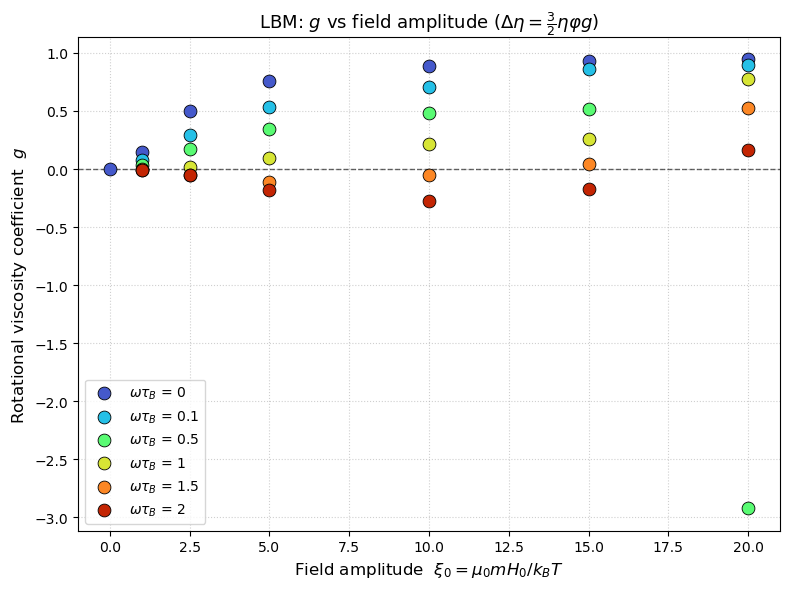

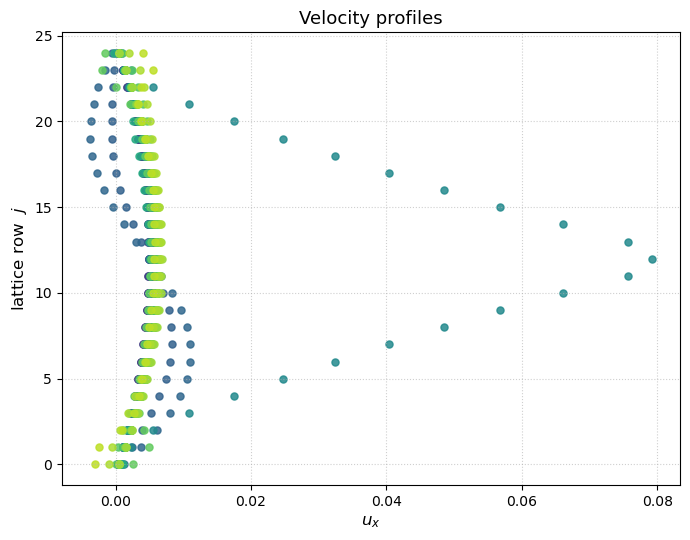

In [5]:
"""
Post-processing for phaseField_poiseuille.cpp.

The viscosity comes from the mass flow rate at a single driving force.  The
Poiseuille line passes through the origin exactly -- zero force gives zero
flow, with no offset to fit -- so one (F, Q) pair determines the slope:

    Q(F) = rho * S * F / (2 eta)        =>      eta = rho * S * F / (2 Q)

with  Q = sum_j rho_j ux_j  (mass flow per unit width) and

    S = sum_j (j + 1/2)(nY - 1/2 - j)

evaluated as the exact DISCRETE sum, not the continuum nY^3/6.  Using the
continuum value biases every eta by ~0.08%, which does not cancel in the
ratio below and gets amplified by 2/(3 phi_p) = 3.33 on its way into g.
With the discrete S a zero-field run returns eta_h exactly.

Then, from Bacri Eq. (10), Delta_eta = (3/2) eta phi_p g, so

    g = (2 / (3 phi_p)) * (eta - eta_0) / eta_0
"""

import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# 1. Configuration -- must match the C++ globals
# ----------------------------------------------------------------------
BASE_DIR = "output_poiseuille_corrected"  # folder containing the run subfolders

nY    = 25       # channel height in lattice nodes
phi_p = 0.2      # PARTICLE volume fraction (the theory's phi)
eta_h = 0.05     # field-free dynamic viscosity

# Rows to drop at each wall when checking the profile shape.  My_safe()
# extrapolates linearly, exact for the continuum solution but not quite for
# the bounce-back node.  This affects the DIAGNOSTIC only, never eta.
NEDGE = 1

FOLDER_RE = re.compile(r"output_xi0_(-?[\d.]+)_wtB_(-?[\d.]+)")

# Discrete cross-section factor
_j = np.arange(nY)
S_DISCRETE = float(np.sum((_j + 0.5) * (nY - 0.5 - _j)))


# ----------------------------------------------------------------------
# 2. Load
# ----------------------------------------------------------------------
def latest_csv(folder):
    """Newest output_t_*.csv in a run folder, by iteration number."""
    files = glob.glob(os.path.join(folder, "output_t_*.csv"))
    if not files:
        return None, None

    def it_of(p):
        m = re.search(r"output_t_(\d+)\.csv$", p)
        return int(m.group(1)) if m else -1

    best = max(files, key=it_of)
    return best, it_of(best)


def read_run(csv_path):
    df = pd.read_csv(csv_path, skipinitialspace=True)
    prof = df.groupby("j").agg(ux=("ux", "mean"),
                               rho=("rho", "mean")).sort_index()
    y   = prof.index.to_numpy(dtype=float)
    ux  = prof["ux"].to_numpy()
    rho = prof["rho"].to_numpy()
    Q   = float(np.sum(rho * ux))
    F   = float(df["Fb_x"].mean())
    return F, Q, float(rho.mean()), y, ux


def parabola_residual(y, ux):
    """
    Relative RMS deviation from a parabola.  g is independent of Omega only
    at leading order in Omega*tau_B; outside that regime g becomes
    shear-dependent and the profile stops being parabolic.  This is the cheap
    way to notice.
    """
    yi = y[NEDGE:len(y) - NEDGE]
    ui = ux[NEDGE:len(ux) - NEDGE]
    basis = (yi + 0.5) * (nY - 0.5 - yi)
    amp = float(np.sum(basis * ui) / np.sum(basis * basis))
    resid = ui - amp * basis
    scale = np.max(np.abs(ui)) if np.max(np.abs(ui)) > 0 else 1.0
    return float(np.sqrt(np.mean(resid ** 2)) / scale)


# ----------------------------------------------------------------------
# 3. Build the results table
# ----------------------------------------------------------------------
if not os.path.isdir(BASE_DIR):
    raise SystemExit(f"No such directory: {BASE_DIR}")

rows = []
for name in sorted(os.listdir(BASE_DIR)):
    folder = os.path.join(BASE_DIR, name)
    if not os.path.isdir(folder):
        continue
    m = FOLDER_RE.match(name)
    if not m:
        continue
    xi0, wtB = float(m.group(1)), float(m.group(2))

    csv_path, it = latest_csv(folder)
    if csv_path is None:
        print(f"  skip {name}: no CSV")
        continue
    try:
        F, Q, rho, y, ux = read_run(csv_path)
    except Exception as e:
        print(f"  skip {name}: {e}")
        continue
    if not np.isfinite(Q) or abs(Q) < 1e-30 or abs(F) < 1e-30:
        print(f"  skip {name}: F={F:g}, Q={Q:g}")
        continue

    rows.append(dict(xi0=xi0, wtB=wtB, iter=it, F=F, Q=Q, rho=rho,
                     eta=rho * S_DISCRETE * F / (2.0 * Q),
                     resid=parabola_residual(y, ux),
                     umax=float(np.max(ux)), y=y, ux=ux))

if not rows:
    raise SystemExit(f"No usable runs found under {BASE_DIR}/")

res = pd.DataFrame(rows).sort_values(["wtB", "xi0"]).reset_index(drop=True)

print(f"Found {len(res)} run(s) in {BASE_DIR}/")
print(f"Discrete cross-section factor S = {S_DISCRETE:.4f} "
      f"(continuum nY^3/6 = {nY ** 3 / 6:.4f})\n")

# Zero-field reference.  At xi0 = 0 the C++ sets Ms = 0, so M = 0 and the flow
# is pure Poiseuille -- that run measures eta(0,0) directly, which is what
# Bacri normalise by.  Fall back to nominal eta_h if it wasn't run.
zero = res[np.isclose(res["xi0"], 0.0)]
if len(zero):
    eta0 = float(zero["eta"].mean())
    print(f"eta(0,0) from the xi0 = 0 run: {eta0:.6f}  "
          f"(nominal {eta_h:.6f}, {100 * (eta0 / eta_h - 1):+.3f}%)\n")
else:
    eta0 = eta_h
    print(f"No xi0 = 0 run found; using nominal eta_h = {eta_h:.6f}.\n"
          f"  Worth running one: it measures the LBM baseline directly, and\n"
          f"  any error there propagates into every g.\n")

res["g"] = (2.0 / (3.0 * phi_p)) * (res["eta"] - eta0) / eta0

with pd.option_context("display.width", 200, "display.max_columns", 20):
    print(res[["xi0", "wtB", "iter", "F", "Q", "eta", "g", "resid"]]
          .to_string(index=False,
                     formatters={"F": "{:.2e}".format, "Q": "{:.6e}".format,
                                 "eta": "{:.6f}".format, "g": "{:+.4f}".format,
                                 "resid": "{:.2e}".format}))

bad = res[res["resid"] > 1e-3]
if len(bad):
    print(f"\nWARNING: {len(bad)} case(s) deviate from a parabola by >0.1%, "
          f"so g may be shear-dependent there\n  (i.e. Omega*tau_B no longer "
          f"<< 1).  Lower Fb_x and re-check.")


# ----------------------------------------------------------------------
# 4. g vs xi0, one series per omega*tau_B   (Bacri Fig. 3 layout)
# ----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
wtBs = sorted(res["wtB"].unique())
colors = plt.cm.turbo(np.linspace(0.1, 0.9, max(1, len(wtBs))))

for c, wtB in zip(colors, wtBs):
    sub = res[res.wtB == wtB].sort_values("xi0")
    ax.scatter(sub["xi0"], sub["g"], s=85, color=c, edgecolors="k",
               linewidths=0.6, zorder=3, label=rf"$\omega\tau_B$ = {wtB:g}")

ax.axhline(0, color="k", lw=1.0, ls="--", alpha=0.6)
ax.set_xlabel(r"Field amplitude  $\xi_0 = \mu_0 m H_0 / k_B T$", fontsize=12)
ax.set_ylabel(r"Rotational viscosity coefficient  $g$", fontsize=12)
ax.set_title(r"LBM: $g$ vs field amplitude "
             r"($\Delta\eta = \frac{3}{2}\eta\varphi g$)", fontsize=13)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(fontsize=10, loc="best")
fig.tight_layout()
plt.show()


# ----------------------------------------------------------------------
# 5. Velocity profiles -- confirm they are parabolic
# ----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 5.5))
pcolors = plt.cm.viridis(np.linspace(0.05, 0.9, max(1, len(res))))

for c, r in zip(pcolors, res.itertuples()):
    ax.scatter(r.ux, r.y, s=26, color=c, alpha=0.85,
               label=rf"$\xi_0$={r.xi0:g}, $\omega\tau_B$={r.wtB:g}")

ax.set_xlabel(r"$u_x$", fontsize=12)
ax.set_ylabel(r"lattice row  $j$", fontsize=12)
ax.set_title("Velocity profiles", fontsize=13)
ax.grid(True, linestyle=":", alpha=0.6)
if len(res) <= 12:
    ax.legend(fontsize=8, loc="best")
fig.tight_layout()
plt.show()

# Post Validation, Comparing with theoretical plots

Found 37 run(s) in output_poiseuille_corrected/
Discrete cross-section factor S = 2606.2500 (continuum nY^3/6 = 2604.1667)

eta(0,0) from the xi0 = 0 run: 0.050000  (nominal 0.050000, +0.000%)

Integrating theory for omega*tau_B = 0, 0.1, 0.5, 1, 1.5, 2 ...

 xi0  wtB   iter      eta       g g_theory     dev    resid
 0.0  0.0 100000 0.050000 +0.0000  +0.0000 +0.0000 6.22e-17
 1.0  0.0 100000 0.052133 +0.1422  +0.1426 -0.0004 2.65e-05
 2.5  0.0 100000 0.057462 +0.4975  +0.4989 -0.0014 8.32e-05
 5.0  0.0 100000 0.061399 +0.7600  +0.7621 -0.0021 1.19e-04
10.0  0.0 100000 0.063314 +0.8876  +0.8901 -0.0025 1.34e-04
15.0  0.0 100000 0.063895 +0.9263  +0.9289 -0.0026 1.39e-04
20.0  0.0 100000 0.064173 +0.9449  +0.9475 -0.0027 1.41e-04
 1.0  0.1 100000 0.051116 +0.0744  +0.0721 +0.0023 1.64e-04
 2.5  0.1 100000 0.054454 +0.2969  +0.2889 +0.0080 5.21e-04
 5.0  0.1 100000 0.058008 +0.5339  +0.5234 +0.0105 6.23e-04
10.0  0.1 100000 0.060582 +0.7054  +0.6987 +0.0067 5.32e-04
15.0  0.1 100000 0.06

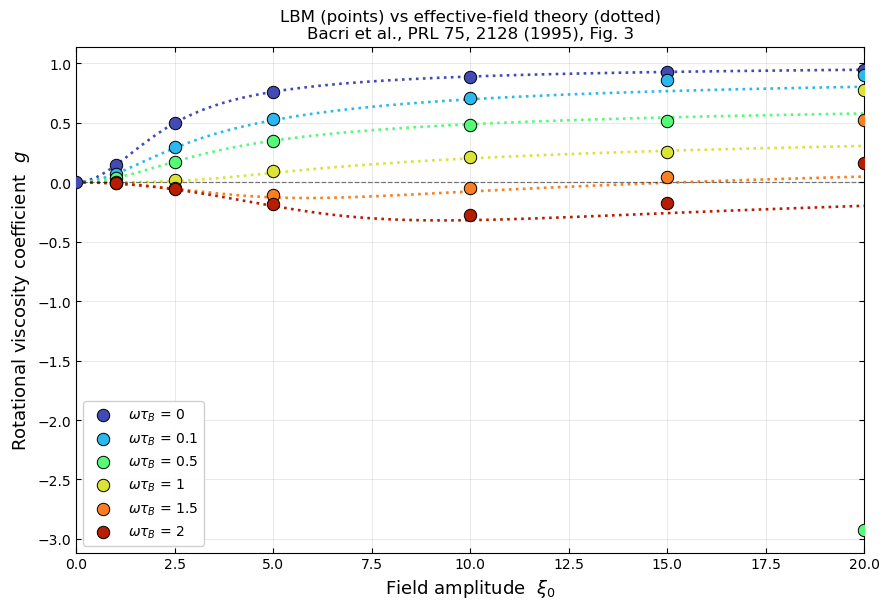

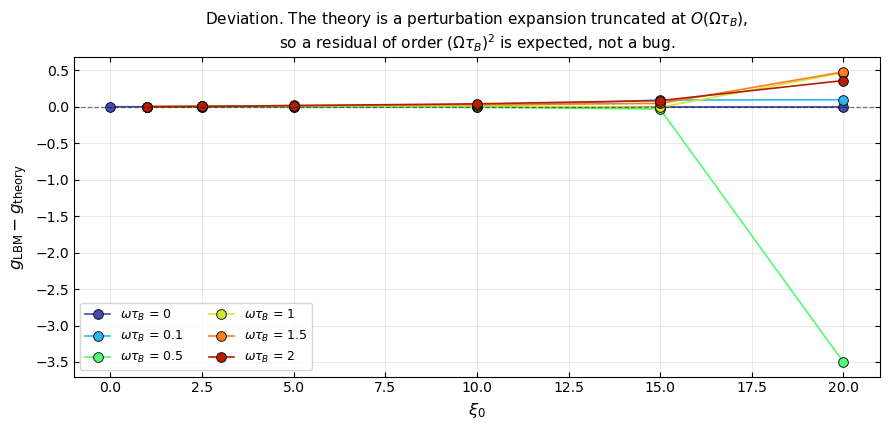

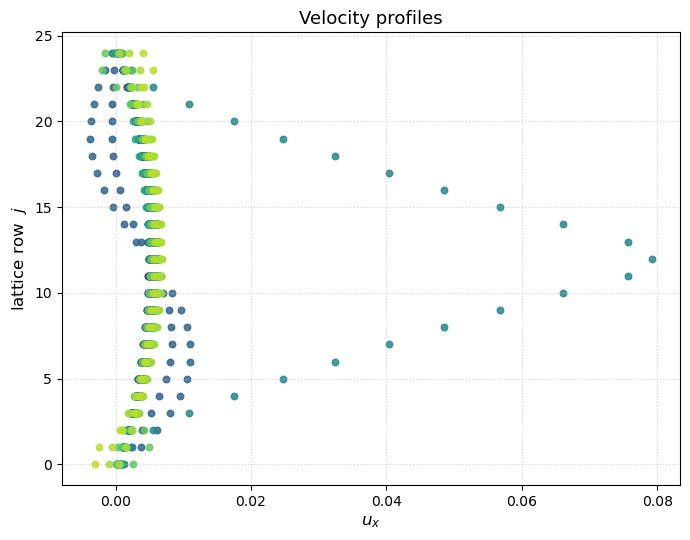

In [6]:
"""
LBM results for the rotational viscosity of a ferrofluid in an alternating
field, overlaid on the effective-field theory of

    J.-C. Bacri, R. Perzynski, M. I. Shliomis, G. I. Burde,
    "Negative-Viscosity Effect in a Magnetic Fluid",
    Phys. Rev. Lett. 75, 2128 (1995)      -- their Fig. 3.

SIMULATION SIDE
    eta = rho * S * F / (2 Q),   Q = sum_j rho_j ux_j,
    S   = sum_j (j + 1/2)(nY - 1/2 - j)      [exact discrete sum]
    g   = (2 / (3 phi_p)) (eta - eta_0) / eta_0     [from Bacri Eq. (10)]

THEORY SIDE
    Bacri Eqs. (7)-(8), integrated with the substitution Y = F * L(xi_e),
    which cancels the 1/xi_e singularity analytically:

        d(xi_e)/dt = -L/L' + [L/(xi_e L')] xi_0 cos(wt)
        dY/dt      =  L(xi_e) - Y [1 - xi_0 cos(wt) B(xi_e)]
        B(x)       =  3/(2x) - 1/(2 L(x))
        g          =  (1/2) xi_0 <Y cos(wt)>

    Time is in units of tau_B, so `wtB` is omega*tau_B directly.
    At wtB = 0 the closed form g = xi_0 L^2 / (xi_0 - L) is used instead.
"""

import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# 1. Configuration -- must match the C++ globals
# ----------------------------------------------------------------------
BASE_DIR = "output_poiseuille_corrected"

nY    = 25       # channel height in lattice nodes
phi_p = 0.2      # PARTICLE volume fraction (the theory's phi)
eta_h = 0.05     # field-free dynamic viscosity

NEDGE = 1        # wall rows dropped in the shape DIAGNOSTIC only

# Theory integration.  h_max caps the step in units of tau_B -- NOT in
# fractions of a period.  The stiffest rate in the ODE is the parallel
# relaxation ~ xi_e/tau_B, which is independent of the drive frequency, so
# splitting the period into a fixed number of steps goes unstable at low
# omega (at omega*tau_B = 0.1 the period is 62.8 tau_B, and 600 steps per
# period puts RK4 right at its stability edge).
H_MAX      = 0.02    # max RK4 step, in tau_B
SETTLE_TAU = 30.0    # transient discarded, in tau_B
AVG_TAU    = 12.0    # averaging window, in tau_B
XI_GRID    = np.linspace(0.0, 20.0, 81)

FOLDER_RE = re.compile(r"output_xi0_(-?[\d.]+)_wtB_(-?[\d.]+)")

_j = np.arange(nY)
S_DISCRETE = float(np.sum((_j + 0.5) * (nY - 0.5 - _j)))


# ======================================================================
# 2. Theory
# ======================================================================
# L is ODD, L' is EVEN, B is ODD.  xi_e passes through zero every time the
# field reverses, so the signs are load-bearing -- computing from |x| and
# forgetting to restore the sign makes the ODE diverge.

def L_vec(x):
    """Langevin function coth(x) - 1/x.  Series below 0.2 avoids the
    cancellation between coth(x) and 1/x; asymptote above 200 avoids
    overflow."""
    x = np.asarray(x, float)
    a = np.abs(x)
    s = np.where(a < 1e-12, 1.0, a)
    ser = a * (1/3 + a**2 * (-1/45 + a**2 * (2/945 - a**2/4725)))
    sc = np.clip(s, None, 200.0)
    ex = np.where(a > 200.0, 1.0 - 1.0/s, 1.0/np.tanh(sc) - 1.0/s)
    return np.sign(x) * np.where(a < 0.2, ser, ex)


def dL_vec(x):
    """L'(x) = 1/x^2 - 1/sinh^2(x)."""
    a = np.abs(np.asarray(x, float))
    s = np.where(a < 1e-12, 1.0, a)
    ser = 1/3 + a**2 * (-1/15 + a**2 * (2/189 - a**2/675))
    sc = np.clip(s, None, 200.0)
    ex = np.where(a > 200.0, 1.0/s**2, 1.0/s**2 - 1.0/np.sinh(sc)**2)
    return np.where(a < 0.2, ser, ex)


def B_vec(x):
    """B(x) = 3/(2x) - 1/(2L(x)).  The crossover to the series sits at 0.05:
    the series error grows like x^7 while the direct form's cancellation
    error goes like eps/x, and they cross near x = 0.025."""
    x = np.asarray(x, float)
    a = np.abs(x)
    s = np.where(a < 1e-12, 1.0, a)
    ser = -a/10.0 + a**3/350.0 - a**5/3500.0
    Lp = L_vec(s)
    return np.sign(x) * np.where(a < 0.05, ser, 1.5/s - 0.5/Lp)


def g_theory(xi0, wtB, h_max=H_MAX, settle_tau=SETTLE_TAU, avg_tau=AVG_TAU):
    """g(xi_0) for one omega*tau_B, vectorised over the xi_0 array."""
    xi0 = np.asarray(xi0, float)
    out = np.zeros_like(xi0)

    if wtB < 1e-12:                       # static field: closed form
        l = L_vec(xi0)
        nz = xi0 > 1e-10
        out[nz] = xi0[nz] * l[nz]**2 / (xi0[nz] - l[nz])
        return out

    T = 2.0 * np.pi / wtB
    N = max(200, int(np.ceil(T / h_max)))
    h = T / N
    n_settle = max(3, int(np.ceil(settle_tau / T)))
    n_avg    = max(2, int(np.ceil(avg_tau / T)))

    xe = xi0.copy()
    Y  = np.zeros_like(xi0)
    I  = np.zeros_like(xi0)
    t  = 0.0

    def fx(t, xe):
        Lv, dLv = L_vec(xe), dL_vec(xe)
        s = np.where(np.abs(xe) < 1e-12, 1.0, xe)
        return -Lv/dLv + (Lv/(s*dLv)) * xi0 * np.cos(wtB*t)

    def fy(t, xe, Y):
        return L_vec(xe) - Y*(1.0 - xi0*np.cos(wtB*t)*B_vec(xe))

    for phase in (0, 1):
        for _ in range(n_settle*N if phase == 0 else n_avg*N):
            c1 = np.cos(wtB*t)
            c2 = np.cos(wtB*(t + h/2))
            c4 = np.cos(wtB*(t + h))
            k1x = fx(t, xe);                    k1y = fy(t, xe, Y)
            k1i = Y*c1
            k2x = fx(t+h/2, xe+h/2*k1x)
            k2y = fy(t+h/2, xe+h/2*k1x, Y+h/2*k1y);  k2i = (Y+h/2*k1y)*c2
            k3x = fx(t+h/2, xe+h/2*k2x)
            k3y = fy(t+h/2, xe+h/2*k2x, Y+h/2*k2y);  k3i = (Y+h/2*k2y)*c2
            k4x = fx(t+h,   xe+h*k3x)
            k4y = fy(t+h,   xe+h*k3x, Y+h*k3y);      k4i = (Y+h*k3y)*c4
            xe = xe + h/6*(k1x + 2*k2x + 2*k3x + k4x)
            Y  = Y  + h/6*(k1y + 2*k2y + 2*k3y + k4y)
            if phase:
                I = I + h/6*(k1i + 2*k2i + 2*k3i + k4i)
            t += h

    return 0.5 * xi0 * I / (n_avg * T)


# ======================================================================
# 3. Simulation
# ======================================================================
def latest_csv(folder):
    files = glob.glob(os.path.join(folder, "output_t_*.csv"))
    if not files:
        return None, None

    def it_of(p):
        m = re.search(r"output_t_(\d+)\.csv$", p)
        return int(m.group(1)) if m else -1

    best = max(files, key=it_of)
    return best, it_of(best)


def read_run(csv_path):
    df = pd.read_csv(csv_path, skipinitialspace=True)
    prof = df.groupby("j").agg(ux=("ux", "mean"),
                               rho=("rho", "mean")).sort_index()
    y   = prof.index.to_numpy(dtype=float)
    ux  = prof["ux"].to_numpy()
    rho = prof["rho"].to_numpy()
    return (float(df["Fb_x"].mean()), float(np.sum(rho*ux)),
            float(rho.mean()), y, ux)


def parabola_residual(y, ux):
    yi = y[NEDGE:len(y)-NEDGE]
    ui = ux[NEDGE:len(ux)-NEDGE]
    basis = (yi + 0.5) * (nY - 0.5 - yi)
    amp = float(np.sum(basis*ui) / np.sum(basis*basis))
    scale = np.max(np.abs(ui)) if np.max(np.abs(ui)) > 0 else 1.0
    return float(np.sqrt(np.mean((ui - amp*basis)**2)) / scale)


if not os.path.isdir(BASE_DIR):
    raise SystemExit(f"No such directory: {BASE_DIR}")

rows = []
for name in sorted(os.listdir(BASE_DIR)):
    folder = os.path.join(BASE_DIR, name)
    if not os.path.isdir(folder):
        continue
    m = FOLDER_RE.match(name)
    if not m:
        continue
    xi0, wtB = float(m.group(1)), float(m.group(2))
    csv_path, it = latest_csv(folder)
    if csv_path is None:
        print(f"  skip {name}: no CSV")
        continue
    try:
        F, Q, rho, y, ux = read_run(csv_path)
    except Exception as e:
        print(f"  skip {name}: {e}")
        continue
    if not np.isfinite(Q) or abs(Q) < 1e-30 or abs(F) < 1e-30:
        print(f"  skip {name}: F={F:g}, Q={Q:g}")
        continue
    rows.append(dict(xi0=xi0, wtB=wtB, iter=it, F=F, Q=Q, rho=rho,
                     eta=rho*S_DISCRETE*F/(2.0*Q),
                     resid=parabola_residual(y, ux), y=y, ux=ux))

if not rows:
    raise SystemExit(f"No usable runs found under {BASE_DIR}/")

res = pd.DataFrame(rows).sort_values(["wtB", "xi0"]).reset_index(drop=True)

print(f"Found {len(res)} run(s) in {BASE_DIR}/")
print(f"Discrete cross-section factor S = {S_DISCRETE:.4f} "
      f"(continuum nY^3/6 = {nY**3/6:.4f})\n")

zero = res[np.isclose(res["xi0"], 0.0)]
if len(zero):
    eta0 = float(zero["eta"].mean())
    print(f"eta(0,0) from the xi0 = 0 run: {eta0:.6f}  "
          f"(nominal {eta_h:.6f}, {100*(eta0/eta_h - 1):+.3f}%)\n")
else:
    eta0 = eta_h
    print(f"No xi0 = 0 run found; using nominal eta_h = {eta_h:.6f}.\n")

res["g"] = (2.0 / (3.0*phi_p)) * (res["eta"] - eta0) / eta0


# ======================================================================
# 4. Theory curves + point-by-point comparison
# ======================================================================
wtBs = sorted(res["wtB"].unique())
print(f"Integrating theory for omega*tau_B = "
      f"{', '.join(f'{w:g}' for w in wtBs)} ...")
curves = {w: g_theory(XI_GRID, w) for w in wtBs}

res["g_theory"] = [g_theory(np.array([x]), w)[0]
                   for x, w in zip(res["xi0"], res["wtB"])]
res["dev"] = res["g"] - res["g_theory"]

print()
with pd.option_context("display.width", 200, "display.max_columns", 20):
    print(res[["xi0", "wtB", "iter", "eta", "g", "g_theory", "dev", "resid"]]
          .to_string(index=False,
                     formatters={"eta": "{:.6f}".format,
                                 "g": "{:+.4f}".format,
                                 "g_theory": "{:+.4f}".format,
                                 "dev": "{:+.4f}".format,
                                 "resid": "{:.2e}".format}))

print(f"\nmax |g_LBM - g_theory| = {res['dev'].abs().max():.4f}"
      f"   (RMS {np.sqrt((res['dev']**2).mean()):.4f})")
print("deviation by frequency:")
for w in wtBs:
    s = res[res.wtB == w]
    print(f"   omega*tau_B = {w:<4g}  max |dev| = {s['dev'].abs().max():.4f}")

bad = res[res["resid"] > 1e-3]
if len(bad):
    print(f"\nWARNING: {len(bad)} case(s) deviate from a parabola by >0.1% "
          f"(Omega*tau_B may no longer be << 1).")


# ======================================================================
# 5. Fig. 3 -- theory dotted, simulation as points
# ======================================================================
fig, ax = plt.subplots(figsize=(9, 6.2))
colors = plt.cm.turbo(np.linspace(0.08, 0.92, max(1, len(wtBs))))

for c, w in zip(colors, wtBs):
    ax.plot(XI_GRID, curves[w], color=c, lw=1.9, ls=":", zorder=2)
    sub = res[res.wtB == w].sort_values("xi0")
    ax.scatter(sub["xi0"], sub["g"], s=80, color=c, edgecolors="k",
               linewidths=0.7, zorder=3,
               label=rf"$\omega\tau_B$ = {w:g}")

ax.axhline(0, color="k", lw=0.9, ls="--", alpha=0.5)
ax.set_xlim(0, XI_GRID.max())
ax.set_xlabel(r"Field amplitude  $\xi_0$", fontsize=13)
ax.set_ylabel(r"Rotational viscosity coefficient  $g$", fontsize=13)
ax.set_title("LBM (points) vs effective-field theory (dotted)\n"
             "Bacri et al., PRL 75, 2128 (1995), Fig. 3", fontsize=12)
ax.tick_params(direction="in", top=True, right=True)
ax.grid(True, lw=0.4, alpha=0.5)
ax.legend(fontsize=10, loc="best", framealpha=0.92)
fig.tight_layout()
plt.savefig("bacri_fig3_lbm.png", dpi=150)
plt.show()


# ======================================================================
# 6. Residual plot -- where the LBM departs from the theory
# ======================================================================
fig, ax = plt.subplots(figsize=(9, 4.4))
for c, w in zip(colors, wtBs):
    sub = res[res.wtB == w].sort_values("xi0")
    ax.plot(sub["xi0"], sub["dev"], "o-", color=c, ms=7, lw=1.2,
            markeredgecolor="k", markeredgewidth=0.6,
            label=rf"$\omega\tau_B$ = {w:g}")

ax.axhline(0, color="k", lw=0.9, ls="--", alpha=0.5)
ax.set_xlabel(r"$\xi_0$", fontsize=12)
ax.set_ylabel(r"$g_{\mathrm{LBM}} - g_{\mathrm{theory}}$", fontsize=12)
ax.set_title(r"Deviation. The theory is a perturbation expansion truncated at "
             r"$O(\Omega\tau_B)$," "\n"
             r"so a residual of order $(\Omega\tau_B)^2$ is expected, not a bug.",
             fontsize=11)
ax.tick_params(direction="in", top=True, right=True)
ax.grid(True, lw=0.4, alpha=0.5)
ax.legend(fontsize=9, ncol=2, loc="best")
fig.tight_layout()
plt.savefig("bacri_fig3_residual.png", dpi=150)
plt.show()


# ======================================================================
# 7. Velocity profiles
# ======================================================================
fig, ax = plt.subplots(figsize=(7, 5.5))
pcolors = plt.cm.viridis(np.linspace(0.05, 0.9, max(1, len(res))))
for c, r in zip(pcolors, res.itertuples()):
    ax.scatter(r.ux, r.y, s=22, color=c, alpha=0.85,
               label=rf"$\xi_0$={r.xi0:g}, $\omega\tau_B$={r.wtB:g}")
ax.set_xlabel(r"$u_x$", fontsize=12)
ax.set_ylabel(r"lattice row  $j$", fontsize=12)
ax.set_title("Velocity profiles", fontsize=13)
ax.grid(True, linestyle=":", alpha=0.6)
if len(res) <= 12:
    ax.legend(fontsize=8, loc="best")
fig.tight_layout()
plt.show()